# Extra EDA for Narrative Analysis Purposes

because we changed all 3 of our research questions I wanted to explore those more in-depth since we haven't really done that yet

In [101]:
import polars as pl
import nflreadpy as nfl
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import seaborn as sns
import plotly.express as px

pbp = nfl.load_pbp(2025)

# may be useful for 4th downs based on professor feedback to include more years, but i'll put it in
# a separate dataset for now
pbpMultYears = nfl.load_pbp([2021, 2022, 2023, 2024, 2025])

playerStats = nfl.load_player_stats(2025)
ngsRecStats = nfl.load_nextgen_stats(2025, stat_type = "receiving")

# additional dataset for team stats, might be useful might not be idk
teamStats = nfl.load_team_stats(2025, "reg")

In [102]:
# filtering pbp to only include relevant data for our questions
pbp = pbp.select([
    "play_type", "yards_gained", "epa", "success", "down", "ydstogo",
    "yardline_100", "qtr", "posteam", "defteam", "game_id", "week"
])
pbpMultYears = pbpMultYears.select([
    "play_type", "yards_gained", "epa", "success", "down", "ydstogo",
    "yardline_100", "qtr", "posteam", "defteam", "game_id", "week"
])

# only include reg season
pbp = pbp.filter(pl.col("week") <= 17)
pbpMultYears = pbpMultYears.filter(pl.col("week") <= 17)

In [103]:
# filtering ngsStats to further include relevant data for our questions (intended air yardage)
ngsRecStats = ngsRecStats.select(["player_gsis_id",
    "player_display_name",
    "player_position",
    "team_abbr",
    "season",
    "week",
    "avg_cushion",
    "avg_separation",
    "yards",
    "avg_yac",
    "avg_expected_yac",
    "avg_yac_above_expectation",
    "avg_intended_air_yards",])

### Question 1: How do rushing and passing success rates individually correlate with NFL team win percentages?

this already has a graph in the original EDA document
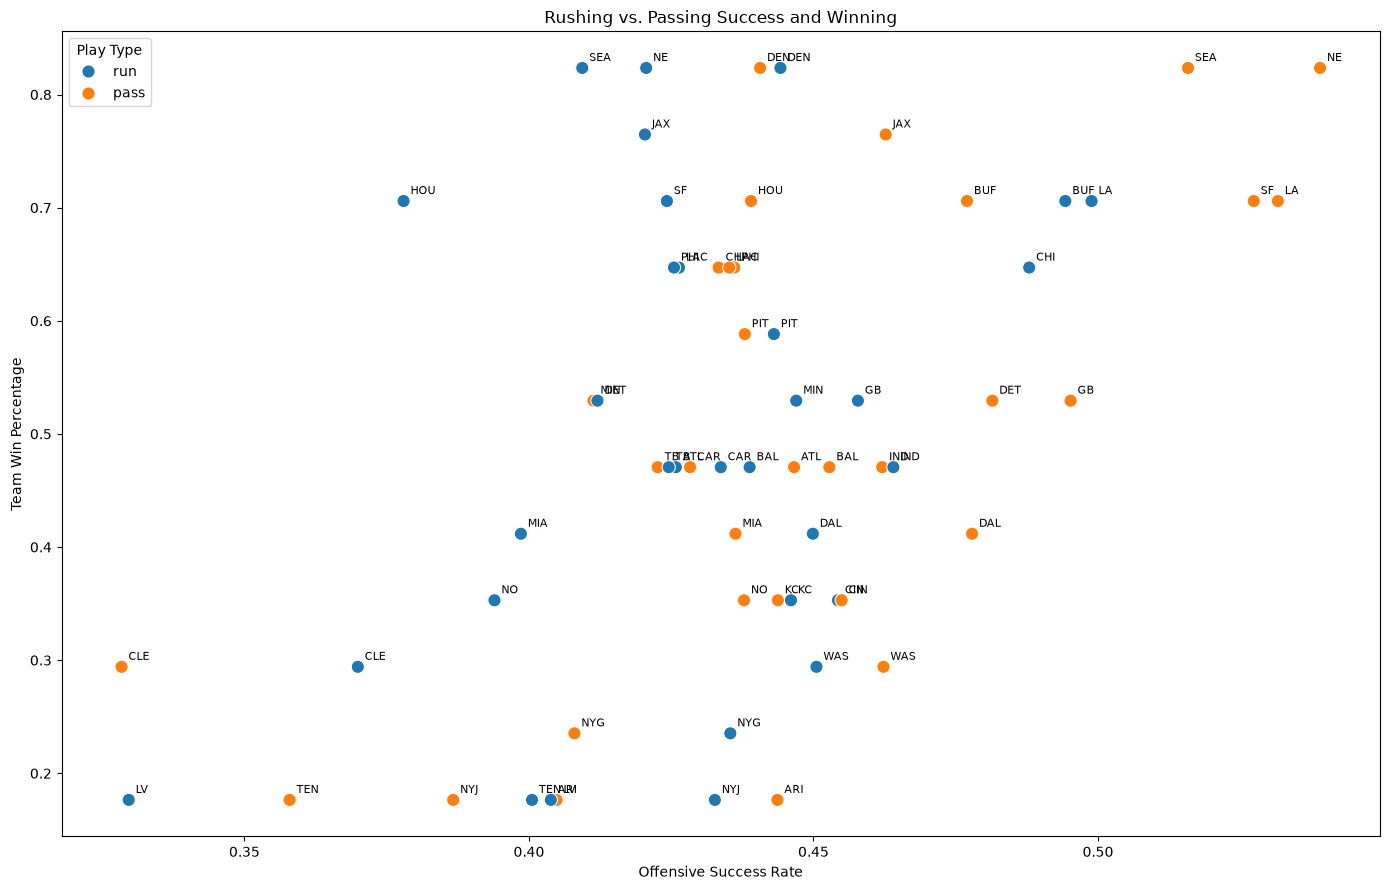

### Question 2: How do yards to go and field position affect the average EPA of punting versus going for it on fourth down?

original EDA document has the 4th down visual but does not include field position in it. the idea here is to try and incorporate how field position changes the rate at which teams go for it or punt, as well as the EPA at each position

aim here is to try to visualize yardage areas of the field (0-20, 20-40, etc.) as individual bin groups, and the x-axis is distance to go and y-axis is average epa/play. this would then be separated into punting or going for it somehow

professor also says it might be a good idea to look at the go rates over multiple years, which i'll probably get to in a separate document because it's out of scope of this question currently

In [104]:
# filter 2021-25 fourth down plays that are punts or actual plays (no fgs)
# doing multiple years is mostly just for the sake of sample size
fourthDowns = pbpMultYears.filter(
    (pl.col("down") == 4)
    & (pl.col("play_type").is_in(["punt", "run", "pass"]))
)
fourthDowns = fourthDowns.with_columns(
    pl.when(pl.col("play_type") == "punt")
    .then(pl.lit("Punt"))
    .otherwise(pl.lit("Go for it"))
    .alias("decision")
)
fourthDowns

play_type,yards_gained,epa,success,down,ydstogo,yardline_100,qtr,posteam,defteam,game_id,week,decision
str,f64,f64,f64,f64,f64,f64,f64,str,str,str,i32,str
"""punt""",0.0,-0.345293,0.0,4.0,10.0,75.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
"""punt""",0.0,0.449995,1.0,4.0,16.0,81.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
"""punt""",0.0,-0.576709,0.0,4.0,3.0,58.0,1.0,"""ARI""","""TEN""","""2021_01_ARI_TEN""",1,"""Punt"""
"""pass""",6.0,3.062272,1.0,4.0,4.0,74.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Go for it"""
"""punt""",0.0,0.006464,1.0,4.0,17.0,75.0,1.0,"""TEN""","""ARI""","""2021_01_ARI_TEN""",1,"""Punt"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""punt""",0.0,0.800151,1.0,4.0,7.0,62.0,4.0,"""TB""","""MIA""","""2025_17_TB_MIA""",17,"""Punt"""
"""punt""",0.0,-0.139205,0.0,4.0,1.0,73.0,4.0,"""MIA""","""TB""","""2025_17_TB_MIA""",17,"""Punt"""
"""punt""",0.0,-0.035621,0.0,4.0,11.0,75.0,4.0,"""MIA""","""TB""","""2025_17_TB_MIA""",17,"""Punt"""


In [105]:
# this fourth down summary code is just lifted from the eda with the addition of
# a column dedicated to field position
fourthSummary = (
    fourthDowns
    .filter(pl.col("ydstogo").is_between(1, 10))
    .group_by(["yardline_100","ydstogo", "decision"])
    .agg([
        pl.col("epa").mean().alias("avg_epa"),
        pl.len().alias("plays")
    ])
    .sort("yardline_100", "ydstogo")
)
fourthSummary.describe()

# combine field position bins into five divisions: 0-20, 21-40, 41-60, 61-80, and 81-100
fourthSummary = fourthSummary.with_columns(
    pl.when(pl.col("yardline_100") <= 20)
    .then(pl.lit("0-20"))
    .when(pl.col("yardline_100") <= 40)
    .then(pl.lit("21-40"))
    .when(pl.col("yardline_100") <= 60)
    .then(pl.lit("41-60"))
    .when(pl.col("yardline_100") <= 80)
    .then(pl.lit("61-80"))
    .otherwise(pl.lit("81-100"))
    .alias("field_position_bin")
)
fourthSummary = fourthSummary.group_by(
    ["field_position_bin", "ydstogo", "decision"]
).agg(
    [
        (pl.col("avg_epa") * pl.col("plays")).sum()
        / pl.col("plays").sum()
        .alias("avg_epa"),
        pl.col("plays").sum().alias("plays")
    ]
).sort("field_position_bin", "ydstogo")
fourthSummary = fourthSummary.filter(
    pl.col("plays") >= 10
)
fourthSummary


field_position_bin,ydstogo,decision,avg_epa,plays
str,f64,str,f64,u32
"""0-20""",1.0,"""Go for it""",-0.068007,455
"""0-20""",2.0,"""Go for it""",0.791654,167
"""0-20""",3.0,"""Go for it""",0.131019,100
"""0-20""",4.0,"""Go for it""",0.618823,64
"""0-20""",5.0,"""Go for it""",-0.041916,41
…,…,…,…,…
"""81-100""",6.0,"""Punt""",-0.265315,94
"""81-100""",7.0,"""Punt""",-0.340201,74
"""81-100""",8.0,"""Punt""",-0.215561,69


In [106]:
plotFourth = fourthSummary.to_pandas()

# create a plot of fourth down decisions by field position and yards to go
# i think the easiest way to do this is to just make two separate plots for going for it and punting
# maybe overlay the two later but idk how to do that yet
plotFourthPunts = plotFourth[plotFourth["decision"] == "Punt"]
plotFourthGoForIt = plotFourth[plotFourth["decision"] == "Go for it"]

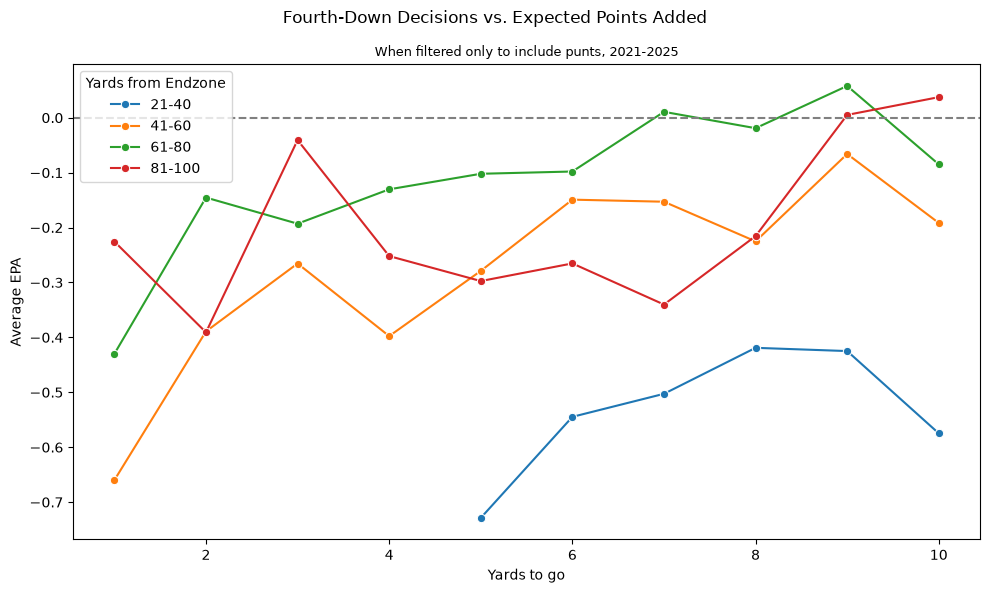

In [107]:
# punting only
plt.figure(figsize = (10,6))
ax1 = sns.lineplot(data=plotFourthPunts, x = "ydstogo", y = "avg_epa",
             hue = "field_position_bin", marker = "o")

plt.axhline(0, color="gray", linestyle="--")
sns.move_legend(ax1, 'upper left', bbox_to_anchor = (0,1), title = "Yards from Endzone")
ax1.set_xlabel("Yards to go")
ax1.set_ylabel("Average EPA")

plt.suptitle("Fourth-Down Decisions vs. Expected Points Added")
plt.title("When filtered only to include punts, 2021-2025", fontsize = 9)
plt.tight_layout()
plt.show()

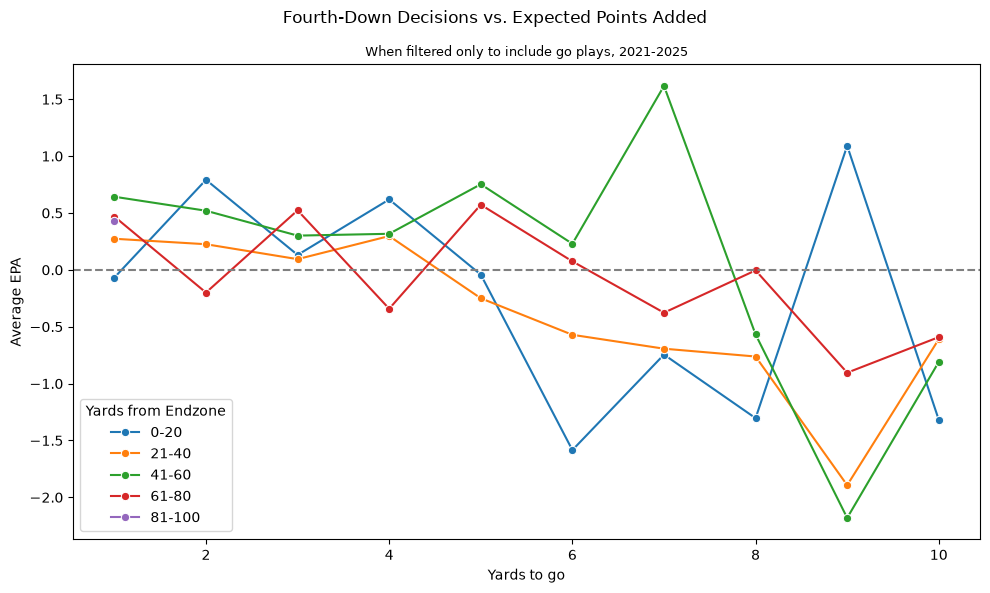

In [108]:
# go only
plt.figure(figsize = (10,6))
ax2 = sns.lineplot(data=plotFourthGoForIt, x = "ydstogo", y = "avg_epa",
             hue = "field_position_bin", marker = "o")

plt.axhline(0, color="gray", linestyle="--")
sns.move_legend(ax2, 'upper left', bbox_to_anchor = (0,0.31), title = "Yards from Endzone")
ax2.set_xlabel("Yards to go")
ax2.set_ylabel("Average EPA")

plt.suptitle("Fourth-Down Decisions vs. Expected Points Added")
plt.title("When filtered only to include go plays, 2021-2025", fontsize = 9)
plt.tight_layout()
plt.show()

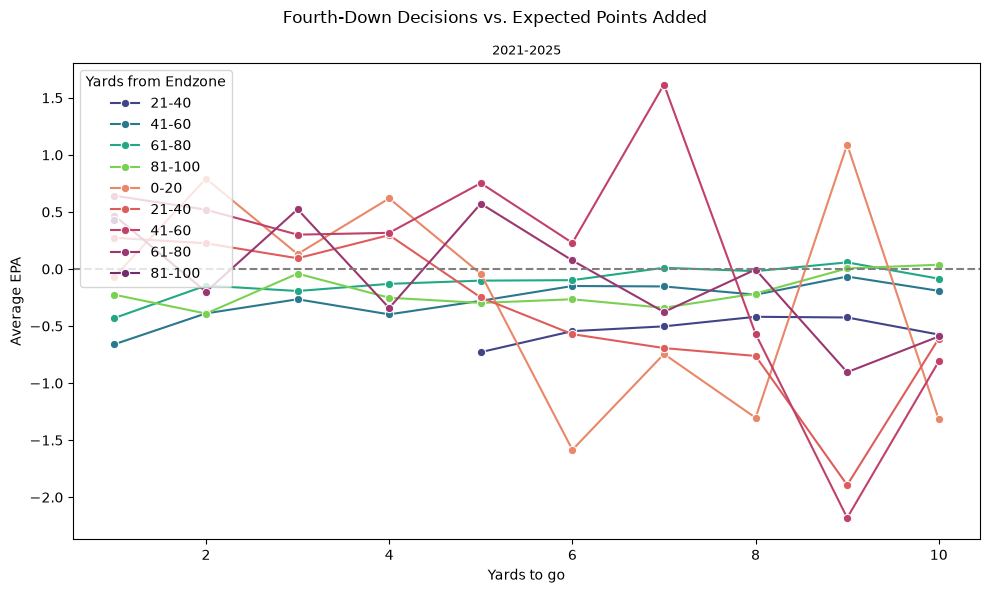

In [119]:
# combined figure
# TODO: fix labels, this is just a rough go for now
fig, ax = plt.subplots(figsize = (10,6))
ax1 = sns.lineplot(data=plotFourthPunts, x = "ydstogo", y = "avg_epa",
             hue = "field_position_bin", marker = "o", ax=ax, palette = "viridis")
ax2 = sns.lineplot(data=plotFourthGoForIt, x = "ydstogo", y = "avg_epa",
             hue = "field_position_bin", marker = "o", ax=ax, palette = "flare")

plt.axhline(0, color="gray", linestyle="--")
sns.move_legend(ax, 'upper left', bbox_to_anchor = (0,1), title = "Yards from Endzone")
ax.set_xlabel("Yards to go")
ax.set_ylabel("Average EPA")

plt.suptitle("Fourth-Down Decisions vs. Expected Points Added")
plt.title("2021-2025", fontsize = 9)
plt.tight_layout()
plt.show()

Punting EPA generally increases when the yards to go is higher, while Going EPA is the opposite.

### Question 3: How does average WR separation correlate with receiving yards per target, and does this relationship change based on route depth?

original EDA document found a pretty inconclusive showing that separation alone is correlated with yards per target, so the idea is to see if depth of target might change this through intended air yards.

this question is unfortunately not possible with the current data we have, where the idea would be that deeper routes matter more/less for separation, not as a whole player average

In [109]:
# calculate yards per target for wrs
recStats = (
    playerStats.select(["player_id",
        "season",
        "week",
        "receiving_yards",
        "targets"
    ])
    .rename({
        "player_id": "player_gsis_id",
        "receiving_yards": "yards",
        "targets": "weekly_targets"
    })
)
recStats = ngsRecStats.join(
    recStats,
    on=["player_gsis_id", "season", "week"],
    how="inner"
)
recStats = recStats.with_columns(
    (pl.col("yards") / pl.col("weekly_targets")).alias("yards_per_target")
)
recStats

player_gsis_id,player_display_name,player_position,team_abbr,season,week,avg_cushion,avg_separation,yards,avg_yac,avg_expected_yac,avg_yac_above_expectation,avg_intended_air_yards,yards_right,weekly_targets,yards_per_target
str,str,str,str,i32,i32,f64,f64,i32,f64,f64,f64,f64,i32,i32,f64
"""00-0030061""","""Zach Ertz""","""TE""","""WAS""",2025,1,6.336,2.454593,26,2.02,1.929988,0.090012,8.252,26,5,5.2
"""00-0030279""","""Keenan Allen""","""WR""","""LAC""",2025,1,5.2,3.497281,68,2.781429,3.122002,-0.340573,8.944,68,10,6.8
"""00-0031381""","""Davante Adams""","""WR""","""LAR""",2025,1,6.7925,1.61925,51,2.545,1.629017,0.915983,8.52875,51,8,6.375
"""00-0031408""","""Mike Evans""","""WR""","""TB""",2025,1,4.985,1.797824,51,0.842,2.138415,-1.296415,13.00375,51,8,6.375
"""00-0031588""","""Stefon Diggs""","""WR""","""NE""",2025,1,3.584,3.373366,57,3.616667,5.465305,-1.848638,7.894286,57,7,8.142857
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""00-0034348""","""Courtland Sutton""","""WR""","""DEN""",2025,21,6.5,2.782492,17,0.283333,0.158608,0.124726,9.318,17,5,3.4
"""00-0038543""","""Jaxon Smith-Njigba""","""WR""","""SEA""",2025,21,4.259,3.29308,153,4.864,3.897939,0.966061,11.451667,153,12,12.75
"""00-0038608""","""Kayshon Boutte""","""WR""","""NE""",2025,21,7.116667,1.507822,6,2.28,1.926855,0.353145,22.04,6,6,1.0


In [110]:
# distribution plots of yards per target and intended air yards
fig = px.box(recStats, x="avg_intended_air_yards")
fig.update_layout(width = 800, height = 600)
fig

In [111]:
# make two separate plots for ypt and separation, grouped by intended air yards.
# split will be at the median of the intended air yards (9.59)
recStatsLowYardage = recStats.filter(pl.col("avg_intended_air_yards") < 9.59)
recStatsHighYardage = recStats.filter(pl.col("avg_intended_air_yards") >= 9.59)

# convert to pandas for seaborn
plot1 = recStatsLowYardage.to_pandas()
plot2 = recStatsHighYardage.to_pandas()

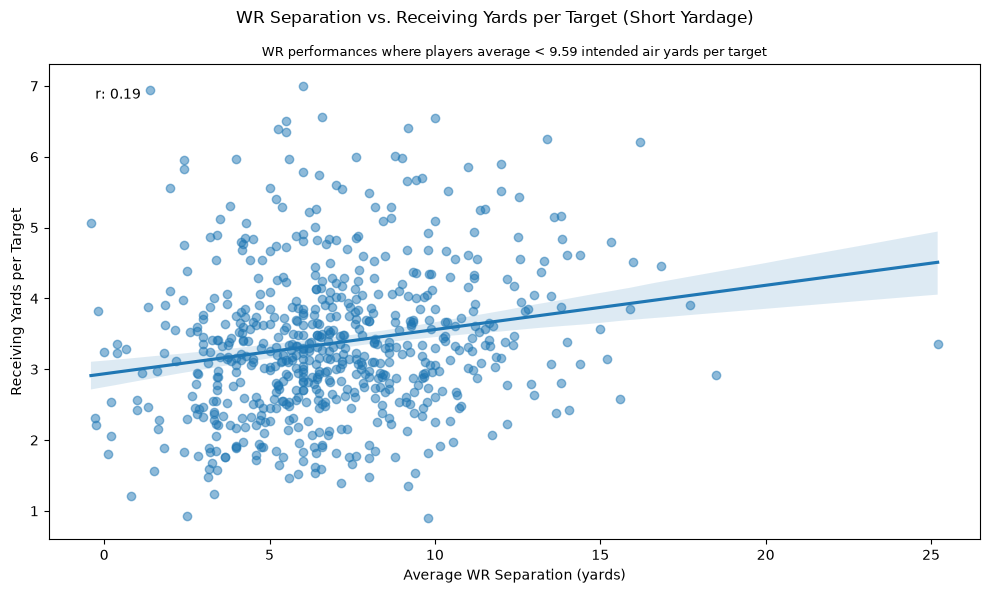

In [112]:
# short yardage depth plot
plt.figure(figsize=(10,6))
sns.regplot(data=plot1,
            x="yards_per_target",
            y="avg_separation",
            scatter_kws = {"alpha": 0.5})

plt.suptitle("WR Separation vs. Receiving Yards per Target (Short Yardage)")
plt.title("WR performances where players average < 9.59 intended air yards per target",
          fontsize = 9)
plt.xlabel("Average WR Separation (yards)")
plt.ylabel("Receiving Yards per Target")

# show correlation coefficient on plot
correlation = plot1["yards_per_target"].corr(plot1["avg_separation"])
plt.text(0.05, 0.95, f"r: {correlation:.2f}", transform=plt.gca().transAxes, va="top")

plt.tight_layout()
plt.show()

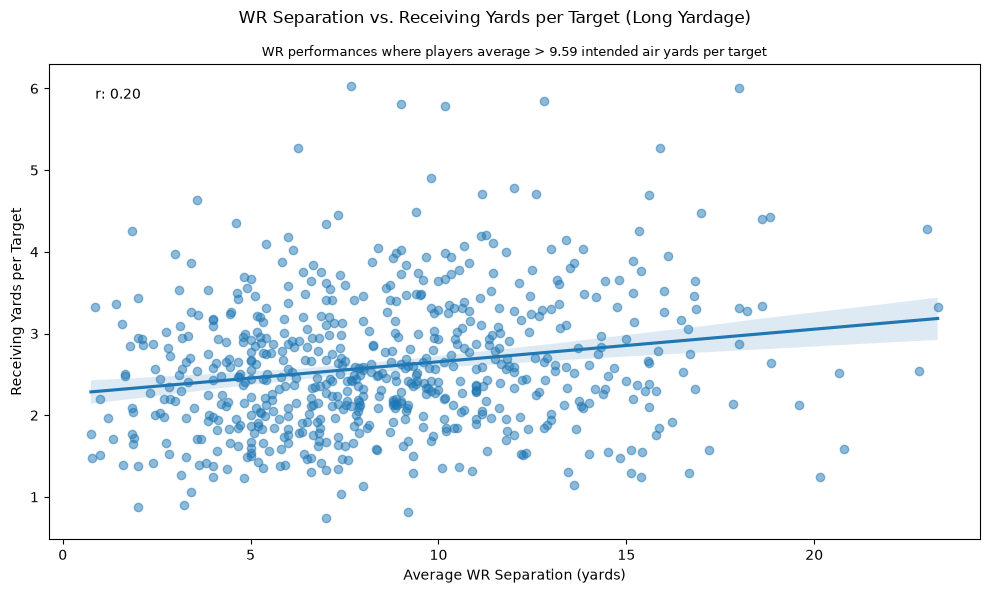

In [113]:
# long yardage depth plot
plt.figure(figsize=(10,6))
sns.regplot(data=plot2,
            x="yards_per_target",
            y="avg_separation",
            scatter_kws = {"alpha": 0.5})

plt.suptitle("WR Separation vs. Receiving Yards per Target (Long Yardage)")
plt.title("WR performances where players average > 9.59 intended air yards per target",
          fontsize = 9)
plt.xlabel("Average WR Separation (yards)")
plt.ylabel("Receiving Yards per Target")

# show correlation coefficient on plot
correlation = plot2["yards_per_target"].corr(plot2["avg_separation"])
plt.text(0.05, 0.95, f"r: {correlation:.2f}", transform=plt.gca().transAxes, va="top")

plt.tight_layout()
plt.show()

Both plots show a similarly weak positive correlation for more separation accounting for more YPT, but the correlation is slightly stronger than it was when unadjusted for air yardage. Interestingly, the intercept is actually around 0.5 yards higher for receivers with lower intended air yards than receivers with higher intended air yards, which could explain the discrepancy. 